# Terra Coletiva — Financial Scenarios, Stress Tests & Worked Examples

Models the collective land fund across: founding alone vs with friends, late joiners (2y / 5y) under different **top-up** strategies, the **buy-cheap → trade-up** path, and **stress tests** (withdrawals, a run on the reserve, appreciation/depreciation, asymmetric contributions, defaults).

**Everything is illustrative** — the numbers are assumptions you change in one place (the `Params` block). The *mechanics* are the point. Imports `financial_model.py` (same folder); needs `pandas` + `matplotlib` (see the project `.venv`).

## Assumptions (single source of truth)

| Parameter | Value | Meaning |
|---|---|---|
| `insurance_rate` | 10% | share of every contribution routed to the **insurance reserve** (self-insurance for exits) |
| `standard_monthly` | R$ 1.500 | monthly contribution of **one full share** (a family = 1 share; a single friend = 1 share) |
| `horizon_months` | 120 | 10 years |
| `land_tiers` | R$ 300k → 800k → 1.5M | entry (cheap) → bigger → **ideal** |
| `land_appreciation_annual` | 0% | flat land value (conservative; flip it to test) |
| `rental_yield_annual` | 0% | rent (as % of land value) **reinvested into the fund**, never distributed |

> **Ideal size** = **10 families × R$ 150k of land each = R$ 1.5M** (tier 3). Tiers are intermediate purchase targets on the way there.

**Withdrawal assumption** (documented): an exit pays the member's *nominal principal* (their land-reserve contribution), funded **cash first → insurance reserve → partial land sale** as the last resort.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import financial_model as fm

plt.rcParams['figure.dpi'] = 110

P = fm.Params(
    insurance_rate=0.10,
    standard_monthly=1500.0,
    horizon_months=120,
    land_tiers=(300_000.0, 800_000.0, 1_500_000.0),
    land_appreciation_annual=0.0,
)
print('Model loaded. Defaults:', P)

Model loaded. Defaults: Params(insurance_rate=0.1, standard_monthly=1500.0, horizon_months=120, land_tiers=(300000.0, 800000.0, 1500000.0), land_appreciation_annual=0.0, rental_yield_annual=0.0)


## 1. Scenarios: who's in, from when

- **Scenario A** — *"I found it alone, with my family"* → 1 unit.
- **Scenario B** — *"one more family and a single friend"* → 3 units from the start.
- **Ideal scale** — 10 families, all founders (to show the full trade-up path).

A `unit` = one full share. Contributions are constant unless a late-joiner strategy says otherwise.

In [2]:
def run(*members):
    return fm.simulate(list(members), P)

# Scenario A — I found it alone, with my family (1 unit)
A = run(fm.Member('Familia R', 0))

# Scenario B — + one more family and a single friend (3 units)
B = run(fm.Member('Familia R', 0), fm.Member('Familia B', 0), fm.Member('Amigo C', 0))

# Ideal scale — 10 families, all founders
IDEAL = run(*[fm.Member(f'F{i}', 0) for i in range(1, 11)])

print('Scenario A (1 unit)   milestones:', fm.milestones(A, P))
print('Scenario B (3 units)  milestones:', fm.milestones(B, P))
print('IDEAL (10 units)      milestones:', fm.milestones(IDEAL, P))

Scenario A (1 unit)   milestones: {1: None, 2: None, 3: None}
Scenario B (3 units)  milestones: {1: 75, 2: None, 3: None}
IDEAL (10 units)      milestones: {1: 23, 2: 60, 3: 112}


## 2. Constant members — where the money goes

Stacked: **cash** (land reserve, not yet spent) + **land owned** + **insurance reserve**. The purple line is the total **land fund** (the stake basis). Dotted grey lines are the land tiers.

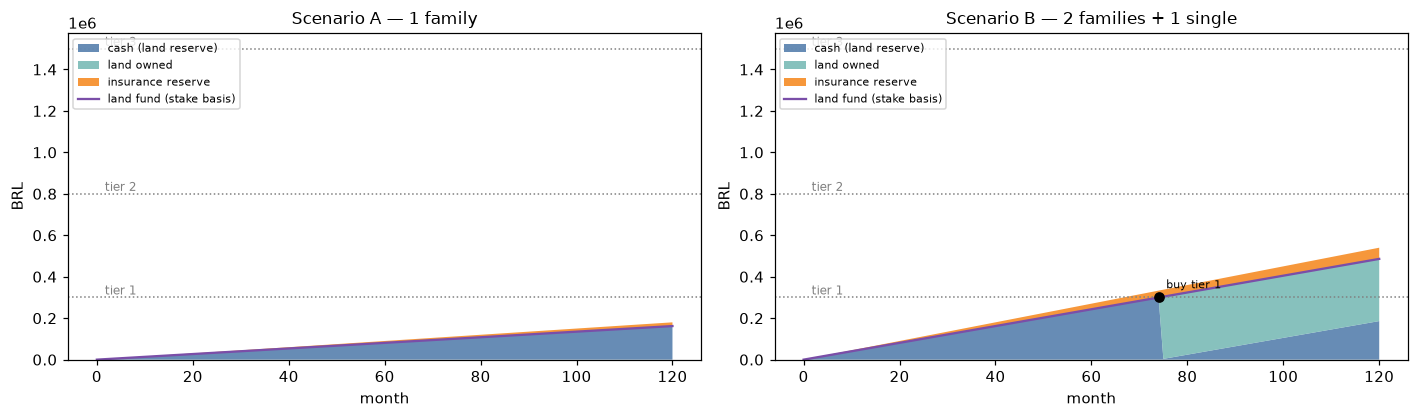

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, (name, df) in zip(axes, [('Scenario A — 1 family', A), ('Scenario B — 2 families + 1 single', B)]):
    m = df.index
    ax.stackplot(m, df['cash'], df['land_asset'], df['insurance_fund'],
                 labels=['cash (land reserve)', 'land owned', 'insurance reserve'],
                 colors=['#4C78A8', '#72B7B2', '#F58518'], alpha=0.85)
    ax.plot(m, df['land_fund'], color='#7A4EA8', lw=1.5, label='land fund (stake basis)')
    for k, price in enumerate(P.land_tiers, start=1):
        ax.axhline(price, color='gray', ls=':', lw=1)
        ax.text(0, price, f'  tier {k}', fontsize=8, va='bottom', color='gray')
    for (mo, ev, tk, price) in df.attrs['events']:
        if ev in ('buy', 'upgrade'):
            ax.scatter([mo], [price], color='black', zorder=5)
            ax.annotate(f'{ev} tier {tk}', (mo, price), fontsize=7, xytext=(5, 6), textcoords='offset points')
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('month'); ax.set_ylabel('BRL')
    ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.show()

In [4]:
rows = []
for name, df in [('A (1 unit)', A), ('B (3 units)', B), ('IDEAL (10 units)', IDEAL)]:
    ms = fm.milestones(df, P)
    rows.append({
        'scenario': name,
        'final land fund': fm.fmt_brl(df['land_fund'].iloc[-1]),
        'insurance reserve': fm.fmt_brl(df['insurance_fund'].iloc[-1]),
        'land owned (10y)': fm.fmt_brl(df['land_asset'].iloc[-1]),
        'cash left': fm.fmt_brl(df['cash'].iloc[-1]),
        'tier 1 @': f"month {ms[1]}" if ms[1] is not None else '—',
        'tier 2 @': f"month {ms[2]}" if ms[2] is not None else '—',
        'tier 3 @': f"month {ms[3]}" if ms[3] is not None else '—',
    })
display(pd.DataFrame(rows).set_index('scenario'))

,final land fund,insurance reserve,land owned (10y),cash left,tier 1 @,tier 2 @,tier 3 @
scenario,,,,,,,
A (1 unit),R$ 162.000,R$ 18.000,R$ 0,R$ 162.000,—,—,—
B (3 units),R$ 486.000,R$ 54.000,R$ 300.000,R$ 186.000,month 75,—,—
IDEAL (10 units),R$ 1.620.000,R$ 180.000,R$ 1.500.000,R$ 120.000,month 23,month 60,month 112


## 3. Late joiners — three top-up strategies

A **new member joins after 2 or 5 years**, on top of the 3 founding units. Three ways to enter:

- **backpay** — pays a lump sum equal to the months they missed, then the standard pace → **full parity** (25%).
- **accelerated** — no lump; pays **2× monthly** until their land contribution catches up to a founder's → reaches parity over time.
- **reduced** — no lump; standard pace from their join date → a **permanently smaller share**.

The grey dashed line is the **equal 4-way split (25%)** — where a "full" member sits.

In [5]:
BASE = [fm.Member('Familia R', 0), fm.Member('Familia B', 0), fm.Member('Amigo C', 0)]

def late_join_sims(join_month):
    return {
        'backpay': run(*BASE, fm.Member('novo_backpay', join_month, strategy='backpay')),
        'accelerated': run(*BASE, fm.Member('novo_accelerated', join_month, strategy='accelerated', accel_factor=2.0)),
        'reduced': run(*BASE, fm.Member('novo_reduced', join_month, strategy='reduced')),
    }

join24 = late_join_sims(24)
join60 = late_join_sims(60)

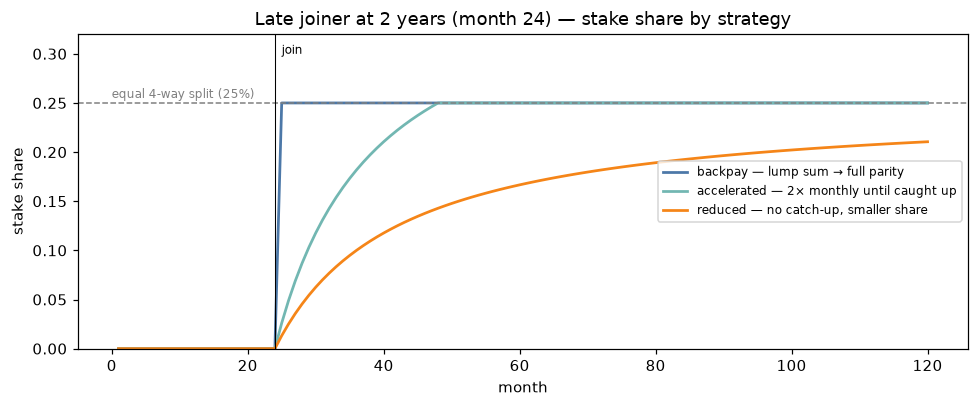

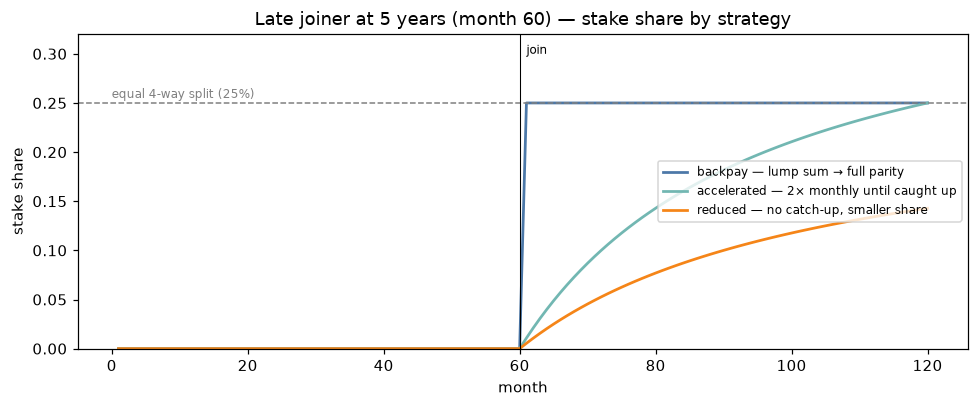

In [6]:
def plot_join(join_sims, join_month, title):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    m = join_sims['backpay'].index
    style = {'backpay': ('#4C78A8', 'backpay — lump sum → full parity'),
             'accelerated': ('#72B7B2', 'accelerated — 2× monthly until caught up'),
             'reduced': ('#F58518', 'reduced — no catch-up, smaller share')}
    for strat, (c, lab) in style.items():
        ax.plot(m, join_sims[strat][f'stake_novo_{strat}'], color=c, lw=1.8, label=lab)
    ax.axhline(0.25, color='gray', ls='--', lw=1)
    ax.text(0, 0.252, 'equal 4-way split (25%)', fontsize=8, va='bottom', color='gray')
    ax.axvline(join_month, color='black', lw=0.7)
    ax.text(join_month + 1, 0.30, 'join', fontsize=8)
    ax.set_xlabel('month'); ax.set_ylabel('stake share'); ax.set_ylim(0, 0.32)
    ax.set_title(title); ax.legend(fontsize=8, loc='center right')
    plt.tight_layout(); plt.show()

plot_join(join24, 24, 'Late joiner at 2 years (month 24) — stake share by strategy')
plot_join(join60, 60, 'Late joiner at 5 years (month 60) — stake share by strategy')

In [7]:
rows = []
for label, sims in [('2 years (24)', join24), ('5 years (60)', join60)]:
    for strat, df in sims.items():
        rows.append({
            'join': label, 'strategy': strat,
            'final stake': f"{df[f'stake_novo_{strat}'].iloc[-1]:.1%}",
            'total paid (10y)': fm.fmt_brl(df[f'total_novo_{strat}'].iloc[-1]),
            'land contributed': fm.fmt_brl(df[f'land_novo_{strat}'].iloc[-1]),
        })
display(pd.DataFrame(rows))

,join,strategy,final stake,total paid (10y),land contributed
0,2 years (24),backpay,25.0%,R$ 180.000,R$ 162.000
1,2 years (24),accelerated,25.0%,R$ 180.000,R$ 162.000
2,2 years (24),reduced,21.1%,R$ 144.000,R$ 129.600
3,5 years (60),backpay,25.0%,R$ 180.000,R$ 162.000
4,5 years (60),accelerated,25.0%,R$ 180.000,R$ 162.000
5,5 years (60),reduced,14.3%,R$ 90.000,R$ 81.000


## 4. Buy cheap → trade up → ideal size

The group buys the **cheapest tier** as soon as cash allows, then **sells and trades up** as the fund grows. This shows that path for Scenario B (3 units) vs the Ideal scale (10 families).

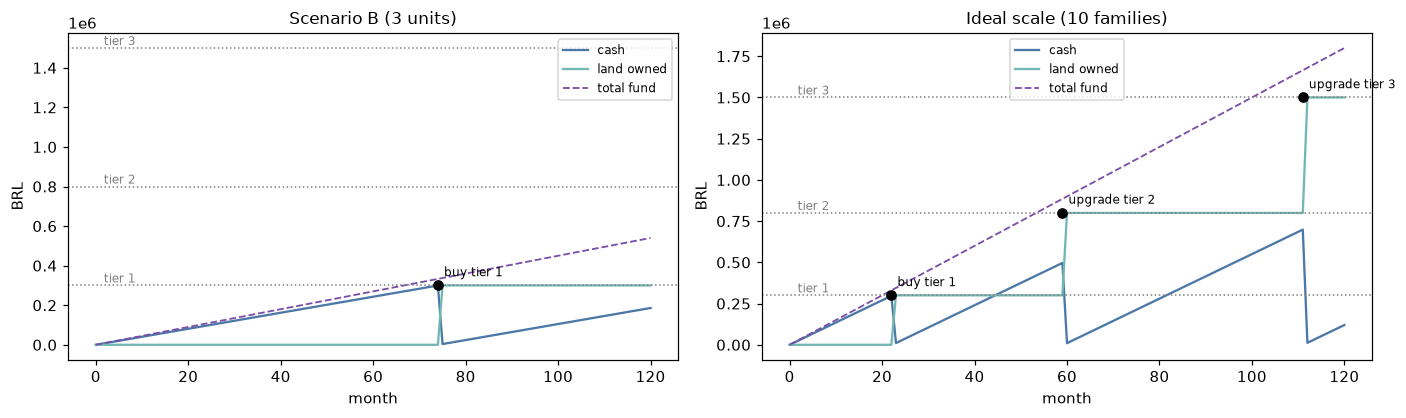

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, (name, df) in zip(axes, [('Scenario B (3 units)', B), ('Ideal scale (10 families)', IDEAL)]):
    m = df.index
    ax.plot(m, df['cash'], color='#4C78A8', lw=1.5, label='cash')
    ax.plot(m, df['land_asset'], color='#72B7B2', lw=1.5, label='land owned')
    ax.plot(m, df['net_worth'], color='#7A4EA8', lw=1.2, ls='--', label='total fund')
    for k, price in enumerate(P.land_tiers, start=1):
        ax.axhline(price, color='gray', ls=':', lw=1)
        ax.text(0, price, f'  tier {k}', fontsize=8, va='bottom', color='gray')
    for (mo, ev, tk, price) in df.attrs['events']:
        if ev in ('buy', 'upgrade'):
            ax.scatter([mo], [price], color='black', zorder=5)
            ax.annotate(f'{ev} tier {tk}', (mo, price), fontsize=8, xytext=(4, 6), textcoords='offset points')
    ax.set_title(name, fontsize=11); ax.set_xlabel('month'); ax.set_ylabel('BRL')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
print('KEY NUMBERS')
print('A (1 family, 10y):   land fund', fm.fmt_brl(A['land_fund'].iloc[-1]),
      '→ cannot even reach tier 1 (R$ 300k).')
print('B (3 units, 10y):    land fund', fm.fmt_brl(B['land_fund'].iloc[-1]),
      '→ reaches tier 1 only; cannot afford tier 2 (R$ 800k).')
print('IDEAL (10 families):  land fund', fm.fmt_brl(IDEAL['land_fund'].iloc[-1]),
      '→ reaches tier 3 (ideal, R$ 1.5M).')
print()
print('To reach tier 2 (R$ 800k) in 10y you need roughly',
      int(np.ceil(800_000 / (120 * 1500 * 0.9))), 'units contributing R$ 1.500/mo;')
print('to reach tier 3 (R$ 1.5M) in 10y you need roughly',
      int(np.ceil(1_500_000 / (120 * 1500 * 0.9))), 'units.')

KEY NUMBERS
A (1 family, 10y):   land fund R$ 162.000 → cannot even reach tier 1 (R$ 300k).
B (3 units, 10y):    land fund R$ 486.000 → reaches tier 1 only; cannot afford tier 2 (R$ 800k).
IDEAL (10 families):  land fund R$ 1.620.000 → reaches tier 3 (ideal, R$ 1.5M).

To reach tier 2 (R$ 800k) in 10y you need roughly 5 units contributing R$ 1.500/mo;
to reach tier 3 (R$ 1.5M) in 10y you need roughly 10 units.


## 5. Stress tests

The scenarios above assume everyone stays and pays. Life doesn't. These stress the structure at its weak points.

### 5.1 Withdrawal timing — before vs after the land purchase

One member exits **before** the land is bought (money still liquid) vs **after** (money tied up in land). The difference is everything.

In [10]:
pre  = fm.simulate([fm.Member('A',0), fm.Member('B',0), fm.Member('C',0, withdraw_month=24)], P)
post = fm.simulate([fm.Member('A',0), fm.Member('B',0), fm.Member('C',0, withdraw_month=90)], P)

for label, df in [('PRE-purchase  (exit month 24)', pre), ('POST-purchase (exit month 90)', post)]:
    e = df.attrs['exits']['C']
    forced = 'YES — forced land sale' if e['from_land'] > 0 else 'no forced sale'
    print(f"{label}: principal {fm.fmt_brl(e['principal'])} | "
          f"cash {fm.fmt_brl(e['from_cash'])} + insurance {fm.fmt_brl(e['from_ins'])} + land {fm.fmt_brl(e['from_land'])} → {forced}")

PRE-purchase  (exit month 24): principal R$ 32.400 | cash R$ 32.400 + insurance R$ 0 + land R$ 0 → no forced sale
POST-purchase (exit month 90): principal R$ 121.500 | cash R$ 67.200 + insurance R$ 40.800 + land R$ 13.500 → YES — forced land sale


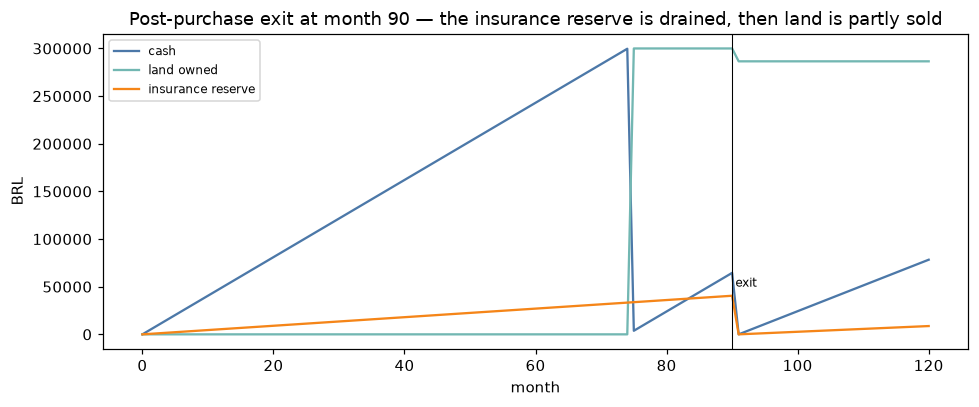

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
m = post.index
ax.plot(m, post['cash'], label='cash', color='#4C78A8')
ax.plot(m, post['land_asset'], label='land owned', color='#72B7B2')
ax.plot(m, post['insurance_fund'], label='insurance reserve', color='#F58518')
ax.axvline(90, color='black', lw=0.7); ax.text(90.5, 50_000, 'exit', fontsize=8)
ax.set_title('Post-purchase exit at month 90 — the insurance reserve is drained, then land is partly sold')
ax.set_xlabel('month'); ax.set_ylabel('BRL'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Run on the reserve — two members exit at once (after purchase)

The worst case for a self-insured pool: two simultaneous exits when the money is in land.

In [12]:
run_df = fm.simulate([fm.Member('A',0, withdraw_month=90), fm.Member('B',0, withdraw_month=90), fm.Member('C',0)], P)
for n, e in run_df.attrs['exits'].items():
    print(f"{n}: principal {fm.fmt_brl(e['principal'])}, from cash {fm.fmt_brl(e['from_cash'])}, "
          f"insurance {fm.fmt_brl(e['from_ins'])}, land sale {fm.fmt_brl(e['from_land'])}")
print('land owned after the run:', fm.fmt_brl(run_df['land_asset'].iloc[-1]), '(was R$ 300.000)')
print('insurance reserve after:', fm.fmt_brl(run_df['insurance_fund'].iloc[-1]))

A: principal R$ 121.500, from cash R$ 65.850, insurance R$ 40.650, land sale R$ 15.000
B: principal R$ 121.500, from cash R$ 0, insurance R$ 0, land sale R$ 121.500
land owned after the run: R$ 163.500 (was R$ 300.000)
insurance reserve after: R$ 4.350


### 5.3 Land price — pessimista vs realista

Nominal depreciation of Brazilian land is rare (recent 5y: +113% — Scot/Canal Rural). So we compare a **pessimistic** 0%/yr (flat nominal = real loss ~4-5%/yr) against a **realistic** +6%/yr (still well below the ~16%/yr recent average).

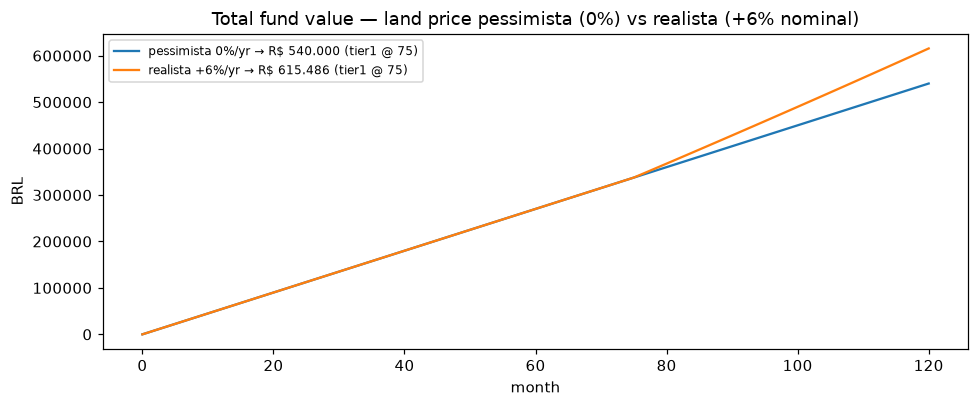

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for label, r in [('pessimista 0%/yr', fm.LAND_APPRECIATION['pessimista']), ('realista +6%/yr', fm.LAND_APPRECIATION['realista'])]:
    p2 = fm.Params(land_appreciation_annual=r)
    d = fm.simulate([fm.Member('A',0), fm.Member('B',0), fm.Member('C',0)], p2)
    ms = fm.milestones(d, p2)
    ax.plot(d.index, d['net_worth'], label=f"{label} → {fm.fmt_brl(d['net_worth'].iloc[-1])} (tier1 @ {ms[1]})")
ax.set_title('Total fund value — land price pessimista (0%) vs realista (+6% nominal)')
ax.set_xlabel('month'); ax.set_ylabel('BRL'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.4 Asymmetric contributions

Three members putting in **2× / 1× / 0.5×** of the standard rate. Stakes should track contributions — that's the proportionality principle, not a bug.

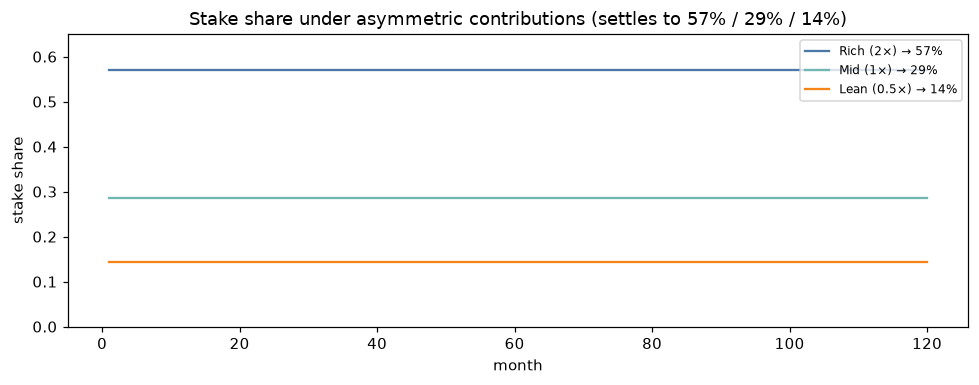

In [14]:
asym = fm.simulate([fm.Member('Rich (2×)',0, monthly=3000), fm.Member('Mid (1×)',0, monthly=1500), fm.Member('Lean (0.5×)',0, monthly=750)], P)
fig, ax = plt.subplots(figsize=(9, 3.6))
m = asym.index
for name, c in [('Rich (2×)', '#4C78A8'), ('Mid (1×)', '#72B7B2'), ('Lean (0.5×)', '#F58518')]:
    ax.plot(m, asym[f'stake_{name}'], color=c, label=f"{name} → {asym[f'stake_{name}'].iloc[-1]:.0%}")
ax.set_title('Stake share under asymmetric contributions (settles to 57% / 29% / 14%)')
ax.set_xlabel('month'); ax.set_ylabel('stake share'); ax.set_ylim(0, 0.65); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.5 Default — a member stops contributing at year 5

They keep their *accumulated* stake (no forfeiture here — that's a policy knob), but it dilutes as the others keep paying.

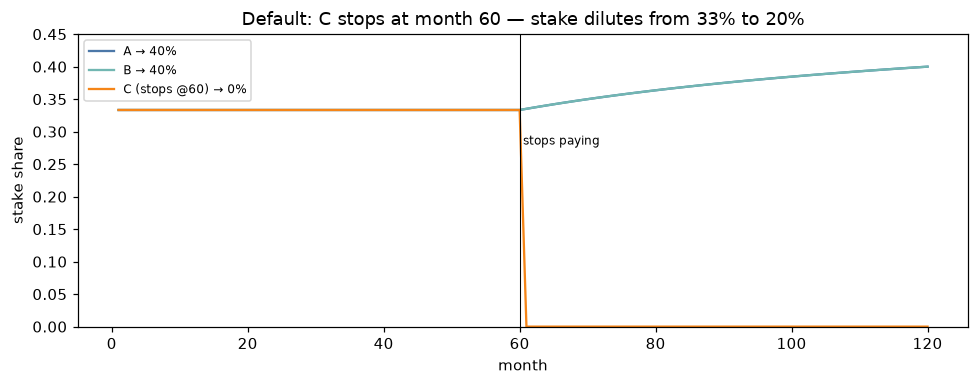

In [15]:
stop = fm.simulate([fm.Member('A',0), fm.Member('B',0), fm.Member('C (stops @60)',0, stop_month=60)], P)
fig, ax = plt.subplots(figsize=(9, 3.6))
for name, c in [('A', '#4C78A8'), ('B', '#72B7B2'), ('C (stops @60)', '#F58518')]:
    ax.plot(stop.index, stop[f'stake_{name}'], color=c, label=f"{name} → {stop[f'stake_{name}'].iloc[-1]:.0%}")
ax.axvline(60, color='black', lw=0.7); ax.text(60.5, 0.28, 'stops paying', fontsize=8)
ax.set_title('Default: C stops at month 60 — stake dilutes from 33% to 20%')
ax.set_xlabel('month'); ax.set_ylabel('stake share'); ax.set_ylim(0, 0.45); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Rental income — social purpose, not profit

Once land is owned it can be rented (to third parties, or to members before they move). **Rental income is reinvested into the fund — never distributed back to participants.** Two effects:

- **Members can stop paying earlier** — rent accelerates the fund toward its target.
- **Hardship buffer** — rent can offset a member's *temporary* pause / postponement.

Reinvesting (not distributing) also **strengthens the legal posture**: no profit flows to members, so the arrangement reads as a collective purpose, not an investment.

In [16]:
p_rent = fm.Params(rental_yield_annual=0.03)
no_rent   = fm.simulate([fm.Member(f'F{i}',0) for i in range(1,11)], P)
with_rent = fm.simulate([fm.Member(f'F{i}',0) for i in range(1,11)], p_rent)

m0 = fm.milestones(no_rent, P); m1 = fm.milestones(with_rent, p_rent)
print('without rent: tier2 @', m0[2], ' tier3 @', m0[3])
print('with 3% rent: tier2 @', m1[2], ' tier3 @', m1[3], ' | rent earned by 10y:', fm.fmt_brl(with_rent['rental_income'].iloc[-1]))
print('→ members stop paying ~', m0[3]-m1[3], 'months earlier (tier 3)')

without rent: tier2 @ 60  tier3 @ 112
with 3% rent: tier2 @ 58  tier3 @ 103  | rent earned by 10y: R$ 180.000
→ members stop paying ~ 9 months earlier (tier 3)


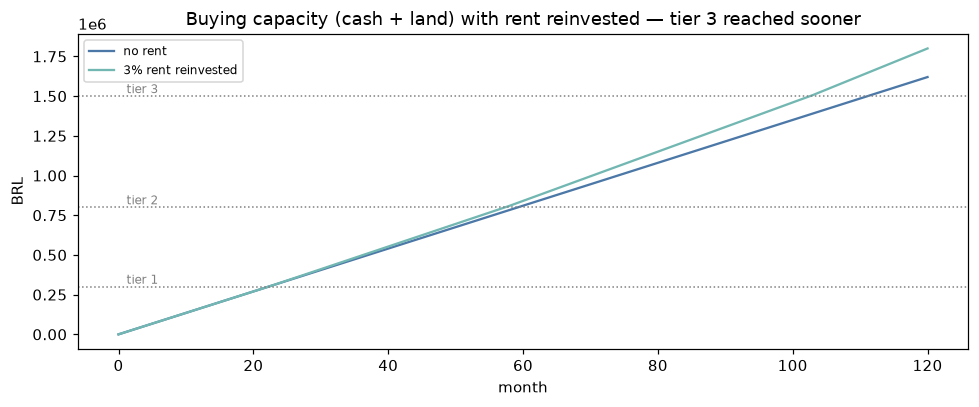

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(no_rent.index, no_rent['cash'] + no_rent['land_asset'], label='no rent', color='#4C78A8')
ax.plot(with_rent.index, with_rent['cash'] + with_rent['land_asset'], label='3% rent reinvested', color='#72B7B2')
for k, price in enumerate(P.land_tiers, start=1):
    ax.axhline(price, color='gray', ls=':', lw=1)
    ax.text(0, price, f'  tier {k}', fontsize=8, va='bottom', color='gray')
ax.set_title('Buying capacity (cash + land) with rent reinvested — tier 3 reached sooner')
ax.set_xlabel('month'); ax.set_ylabel('BRL'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [18]:
pause = [fm.Member('F1',0,pause_months=(24,48))] + [fm.Member(f'F{i}',0) for i in range(2,11)]
p_no  = fm.simulate(pause, P)
p_yes = fm.simulate(pause, p_rent)
print('one member paused 24 months (months 24–48):')
print('  baseline (no pause, no rent): tier2 @ 60,  tier3 @ 112')
print('  pause, no rent              : tier2 @', fm.milestones(p_no, P)[2], ' tier3 @', fm.milestones(p_no, P)[3])
print('  pause + rent                : tier2 @', fm.milestones(p_yes, p_rent)[2], ' tier3 @', fm.milestones(p_yes, p_rent)[3])

one member paused 24 months (months 24–48):
  baseline (no pause, no rent): tier2 @ 60,  tier3 @ 112
  pause, no rent              : tier2 @ 62  tier3 @ 114
  pause + rent                : tier2 @ 60  tier3 @ 105


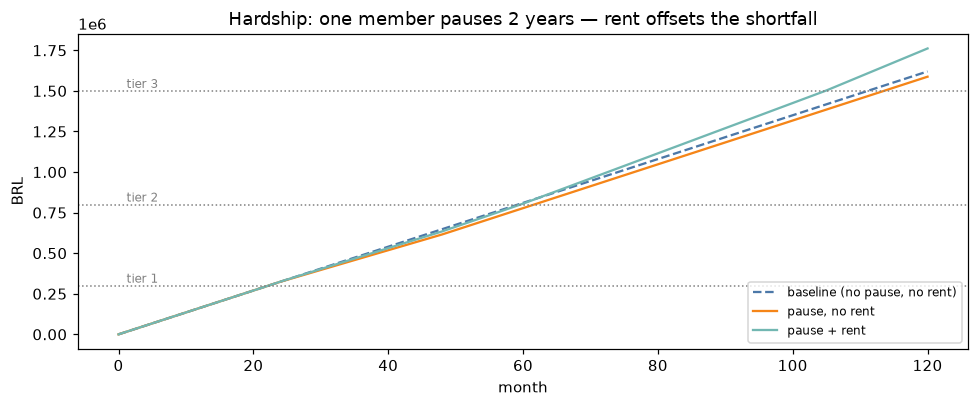

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(no_rent.index, no_rent['cash'] + no_rent['land_asset'], label='baseline (no pause, no rent)', color='#4C78A8', ls='--')
ax.plot(p_no.index, p_no['cash'] + p_no['land_asset'], label='pause, no rent', color='#F58518')
ax.plot(p_yes.index, p_yes['cash'] + p_yes['land_asset'], label='pause + rent', color='#72B7B2')
for k, price in enumerate(P.land_tiers, start=1):
    ax.axhline(price, color='gray', ls=':', lw=1)
    ax.text(0, price, f'  tier {k}', fontsize=8, va='bottom', color='gray')
ax.set_title('Hardship: one member pauses 2 years — rent offsets the shortfall')
ax.set_xlabel('month'); ax.set_ylabel('BRL'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Takeaways

1. **A single family cannot finance even the cheapest tier in 10 years** — the collective is not optional, it's the whole point.
2. **3 units reach only the entry land (tier 1)** at R$ 1.500/mo — bigger land needs more members and/or higher contributions (~5 units for tier 2, ~10 for tier 3).
3. **Late joiners don't break the model.** `backpay` = instant parity; `accelerated` reaches it gradually; `reduced` = permanently smaller share (14.3% vs 25% at 5y).
4. **Withdrawal timing is decisive.** Pre-purchase exits come out of cash (clean). Post-purchase exits drain the insurance reserve and can force a partial land sale.
5. **A run (2 simultaneous exits) after purchase forces selling ~half the land** — this is why the contract needs the payout waterfall, a queue rule, and a reserve sized to a stress case.
6. **The land's price path matters.** Historically Brazilian land *appreciates* (~+16%/yr recent, +113% in 5y); the **pessimistic** planning floor is flat nominal (0%), the **realistic** is +6%/yr.
7. **Asymmetric contributions → proportional stakes** (by design), and **defaults → dilution** (the stopper's stake shrinks, the others' grow).

> Change any assumption in the `Params` block and re-run the whole notebook — every chart and table updates.